# ТК 5-6 (ПР3): kNN — качество красного вина
Метод k ближайших соседей (kNN) - это алгоритм классификации, относящий объект к тому классу, который чаще встречается среди его k ближайших объектов обучающей выборки в пространстве признаков.

Термином «Датасет» называют то, что табличный набор данных, на котором обучается и проверяется модель машинного обучения.

Сплит (train/test, обучающая и тестовая выборки) - это разделение исходного датасета на обучающую и тестовую части, где первая используется для настройки модели, а вторая — для независимой оценки её качества.

Термином «Стратификация (стратифицированное разбиение)» называют то, что способ разбиения данных на части с сохранением исходных пропорций классов в каждой из них.

Используем датасет `docs/winequality-red.csv`, сплит 70/30 со стратификацией.

In [1]:
# Импорты и настройки
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import itertools

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

%matplotlib inline
plt.rcParams["figure.figsize"] = (10,5)

## Загрузка

In [2]:
# Читаем CSV
df = pd.read_csv('docs/winequality-red.csv')

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Описание данных

In [3]:
# Типы столбцов и пропуски
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


## Баланс классов
Баланс классов - это ситуация, при которой классы в выборке представлены примерно одинаковым числом объектов; её отсутствие называют несбалансированностью классов.

На графике ниже показано распределение целевого признака `quality`: по оси x отложены возможные оценки качества вина, по оси y — число образцов с каждой оценкой. Высота столбцов позволяет сразу увидеть, какие классы преобладают, а какие представлены единичными примерами; это важно, потому что на редких классах модель чаще ошибается.

missing cells: 0
full-row duplicates: 240
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


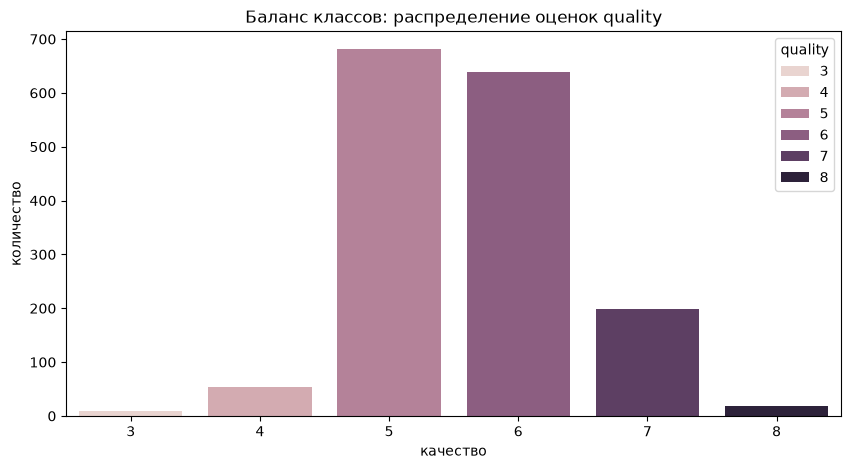

In [4]:
# Распределение оценок
sns.countplot(x='quality', hue='quality', data=df)
plt.xlabel('качество')
plt.ylabel('количество')
plt.title('Баланс классов: распределение оценок quality')

# Проверяем пропуски и дубликаты
print('missing cells:', int(df.isna().sum().sum()))
print('full-row duplicates:', int(df.duplicated().sum()))
print(df['quality'].value_counts().sort_index())

## Функция отрисовки матрицы путаницы
Матрица путаницы - это таблица, в которой строки соответствуют фактическим классам, столбцы — предсказанным, а ячейки содержат число объектов с таким сочетанием.

In [5]:
# Отрисовка матрицы путаницы
def display_confusion_matrix(
    matrix, labels=None,
    title="Матрица путаницы (k=5, тестовая выборка)",
    xlabel="Предсказано",
    ylabel="Фактически",
    figsize=None,
    cmap="Blues",
    vmin=None,
    vmax=None,
):
    if labels is None:
        labels = [""]*len(matrix)
    if vmin is None:
        vmin = 0.
    if vmax is None:
        vmax = np.sum(matrix[0])
    t_hold = (vmax-vmin) / 2.
    fig,ax = plt.subplots(figsize=figsize)
    ax.imshow(matrix, cmap=cmap)
    for row,col in itertools.product(range(len(labels)), range(len(labels))):
        color = "white" if matrix[row,col] > t_hold else "black"
        ax.text(col, row, matrix[row, col], horizontalalignment="center", color=color)
    tick_marks = np.arange(len(labels))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=40, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels)
    plt.show()

## Сплит train/test
Стратификация сохраняет доли классов в обеих выборках.

In [6]:
# Стратифицированный сплит; random_state=42 — для воспроизводимости
X = df.drop(['quality'], axis=1)
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

## Обучение
Термином «Baseline (базовая модель)» называют то, что простая модель или эвристика, служащая отправной точкой для сравнения качества более сложных решений.

k=5 по умолчанию, без масштабирования — baseline.

In [7]:
# kNN, k=5 по умолчанию
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](6,)","[3,4,5,6,7,8]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Метрики
Precision (точность) - это доля объектов, предсказанных положительным классом, которые действительно к нему относятся.
Термином «Recall (полнота)» называют то, что доля объектов положительного класса, которые модель правильно распознала.
F1-мера - это среднее гармоническое точности и полноты, объединяющее обе метрики в одно число.
Термином «Accuracy (доля правильных ответов)» называют то, что доля всех объектов, для которых модель дала правильный прогноз.

Отчёт выводит precision/recall/F1 по классам и общую accuracy.

In [8]:
# Метрики на тесте
preds = knn.predict(X_test)

print(classification_report(y_test, preds))
print('accuracy:', accuracy_score(y_test, preds))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         3
           4       0.00      0.00      0.00        16
           5       0.53      0.61      0.57       204
           6       0.47      0.52      0.49       192
           7       0.34      0.18      0.24        60
           8       0.00      0.00      0.00         5

    accuracy                           0.49       480
   macro avg       0.22      0.22      0.22       480
weighted avg       0.46      0.49      0.47       480

accuracy: 0.4895833333333333


## Матрица путаницы
Строки матрицы соответствуют фактическим оценкам качества, столбцы — прогнозам модели; цвет ячейки и число в ней показывают, сколько образцов получили данную пару «фактический–предсказанный» класс. По диагонали отслеживаются правильные ответы, а вне диагонали видны наиболее частые путаницы, например между соседними оценками 5 и 6.

[[125  71   7   1   0   0]
 [ 81  99  12   0   0   0]
 [ 18  30  11   1   0   0]
 [ 11   5   0   0   0   0]
 [  0   3   2   0   0   0]
 [  1   2   0   0   0   0]]


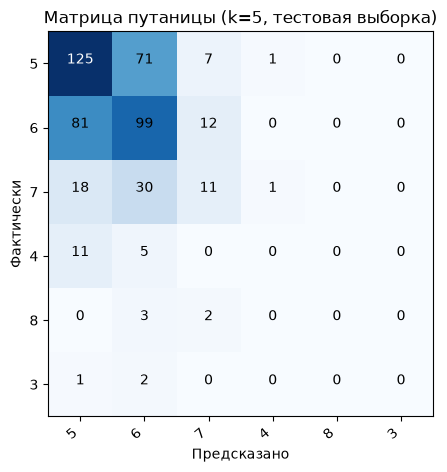

In [9]:
# Матрица путаницы
labels = y.unique()

matrix = confusion_matrix(y_test, preds, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, labels)

## Сводные метрики
Термином «Macro-усреднение» называют то, что способ усреднения метрик по классам с равными весами, не учитывающий число объектов в каждом классе.
Термином «Weighted-усреднение» называют то, что способ усреднения метрик по классам с весами, пропорциональными числу объектов каждого класса.
Термином «Support» называют то, что число объектов тестовой выборки, принадлежащих данному классу.

Per-class P/R/F1 и сводные показатели качества из `wine_knn.py`.

In [10]:
# Сводные метрики из wine_knn.py
import sys; sys.path.insert(0, '.')
from wine_knn import evaluate_knn
res = evaluate_knn('docs/winequality-red.csv')
for m in ('precision','recall','f1'):
    print('per-class ' + m + ':', {k: round(v,3) for k,v in res['per_class'][m].items()})
print('support_test:', res['per_class']['support_test'])
print('macro P/R/F1:', round(res['precision_macro'],4), round(res['recall_macro'],4), round(res['f1_macro'],4))
print('weighted P/R/F1:', round(res['precision_weighted'],4), round(res['recall_weighted'],4), round(res['f1_weighted'],4))
print('OvR AUC macro/weighted:', round(res['roc_auc_ovr_macro'],4), round(res['roc_auc_ovr_weighted'],4))
print('per-class OvR AUC:', {k: round(v,3) for k,v in res['per_class']['roc_auc_ovr'].items()})

per-class precision: {5: 0.53, 6: 0.471, 7: 0.344, 4: 0.0, 8: 0.0, 3: 0.0}
per-class recall: {5: 0.613, 6: 0.516, 7: 0.183, 4: 0.0, 8: 0.0, 3: 0.0}
per-class f1: {5: 0.568, 6: 0.493, 7: 0.239, 4: 0.0, 8: 0.0, 3: 0.0}
support_test: {5: 204, 6: 192, 7: 60, 4: 16, 8: 5, 3: 3}
macro P/R/F1: 0.2241 0.2186 0.2166
weighted P/R/F1: 0.4566 0.4896 0.4684
OvR AUC macro/weighted: 0.6173 0.6521
per-class OvR AUC: {5: 0.689, 6: 0.603, 7: 0.725, 4: 0.519, 8: 0.682, 3: 0.486}


## Полнота по классам
На столбчатой диаграмме по оси x показаны оценки качества вина, а по оси y — значение полноты (recall) для каждого класса на тестовой выборке. Высота столбца отражает долю образцов данного класса, которых модель правильно распознала; низкие или нулевые столбцы указывают на классы, которые kNN почти не находит.

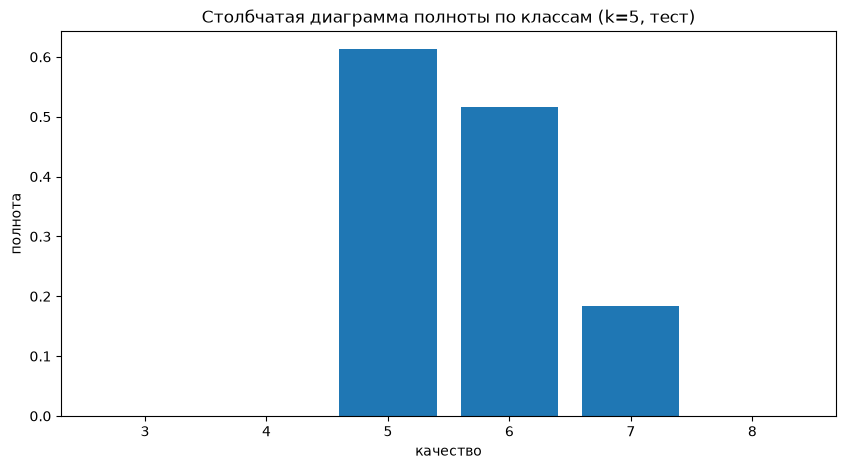

In [11]:
# Полнота по классам
recall_by_class = res['per_class']['recall']
plt.bar(list(recall_by_class.keys()), list(recall_by_class.values()))
plt.xlabel('качество'); plt.ylabel('полнота')
plt.title('Столбчатая диаграмма полноты по классам (k=5, тест)'); plt.show()

## Зависимость от k
Переобучение - это ситуация, когда модель слишком хорошо запоминает обучающую выборку и теряет обобщающую способность на новых данных.

На графике ниже по оси x отложено число соседей k, а по оси y — значения точности на обучающей и тестовой выборках и macro-recall. Разрыв между кривыми train и test позволяет оценить степень переобучения: чем ближе кривые и выше значения на тесте, тем лучше модель обобщается.

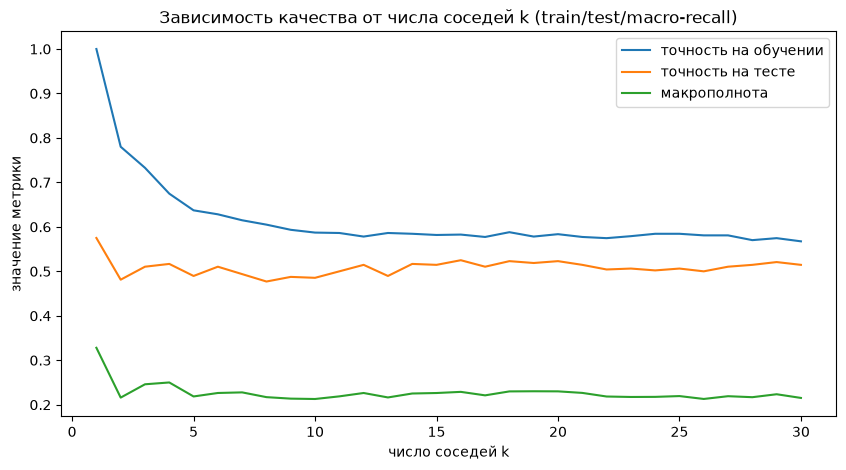

In [12]:
# Точность train/test при k=1..30
from wine_knn import k_sweep
rows = k_sweep('docs/winequality-red.csv')
k_values = [row['k'] for row in rows]
train_accuracy = [row['train_accuracy'] for row in rows]
test_accuracy = [row['test_accuracy'] for row in rows]
recall_macro = [row['recall_macro'] for row in rows]
plt.plot(k_values, train_accuracy, label='точность на обучении')
plt.plot(k_values, test_accuracy, label='точность на тесте')
plt.plot(k_values, recall_macro, label='макрополнота')
plt.xlabel('число соседей k'); plt.ylabel('значение метрики'); plt.legend(); plt.title('Зависимость качества от числа соседей k (train/test/macro-recall)'); plt.show()

## ROC-кривые OvR
ROC-кривая - это график зависимости доли истинноположительных случаев от доли ложноположительных при изменении порога классификации.
AUC - это площадь под ROC-кривой, количественная мера способности модели различать классы.
Термином «Подход OvR (one-vs-rest)» называют то, что способ сведения многоклассовой задачи к набору бинарных задач, где каждый класс отделяется от всех остальных.

На графике для каждого класса построена ROC-кривая в постановке «один против остальных»: по оси x отложена доля ложноположительных ответов (FPR), по оси y — доля истинноположительных (TPR). Пунктирная диагональ соответствует случайному классификатору, а величина AUC в легенде показывает, насколько хорошо модель отделяет данный класс от остальных.

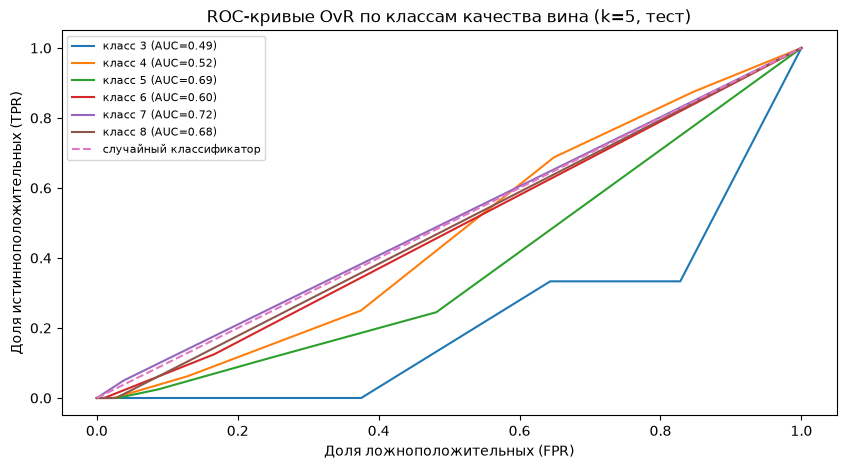

In [13]:
# ROC OvR; AUC — доля верно упорядоченных пар (Дьяконов)
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
classes = res['classes']
y_binarized = label_binarize(res['y_test'], classes=classes)
fig, ax = plt.subplots()
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_binarized[:, i], res['y_proba'][:, i])
    ax.plot(fpr, tpr, label=f'класс {cls} (AUC={res["per_class"]["roc_auc_ovr"][cls]:.2f})')
ax.plot([0, 1], [0, 1], linestyle='--', label='случайный классификатор')
ax.set_xlabel('Доля ложноположительных (FPR)'); ax.set_ylabel('Доля истинноположительных (TPR)'); ax.legend(fontsize=8)
plt.title('ROC-кривые OvR по классам качества вина (k=5, тест)'); plt.show()

## Выводы
Термином «StandardScaler» называют то, что преобразование признаков, вычитающее среднее и делящее на стандартное отклонение для приведения значений к одному масштабу.
Термином «Pipeline» называют то, что последовательность этапов обработки данных и модели, оформленная как единый объект в scikit-learn.

- k=5: accuracy ~0.49 на тесте против ~0.64 на обучении; разрыв уменьшается с ростом k.
- Основная путаница — между оценками 5 и 6; recall классов 3, 4, 8 близок к нулю (в тесте их мало).
- Macro F1 ~0.22, weighted ~0.47 — разница отражает дисбаланс классов.
- OvR AUC macro ~0.62; оценки 3 и 8 нестабильны из-за малых выборок.
- Диапазоны признаков различаются на порядки; вариант улучшения — StandardScaler в Pipeline.